# One PDE, many ways: viscous Burgers through the whole course

Every topic of CPSC 532Z is, in the end, a different answer to the same question: *how do I get the solution of a
PDE?* This notebook takes **one** equation and solves it with each approach from the course, so the differences are
about the methods and not about the problems.

| § | Method | Course topic | What the computer finds |
| --- | --- | --- | --- |
| 1 | Pseudo-spectral solver (+ finite differences) | baseline | nothing learned: the numbers `u(x_i, t_n)` |
| 2 | Differentiable simulation | 01 | the unknown *inputs* (viscosity, initial state), by gradients through the solver |
| 3 | PINN | 02 | one solution `u(x, t)` as a network |
| 4 | POD-Galerkin ROM | 03 | a small linear subspace; the dynamics stay the PDE's |
| 5 | Latent neural ODE | 04 | the time derivative `dz/dt = f(z)` in that subspace |
| 6 | GNS-style graph network | 05 | the time step `u_{t+Δt} = u_t + GNN(u_t)` |
| 7 | Fourier neural operator | 06 | the solution operator `u(·,0) ↦ u(·,T)` |
| 8 | Transolver | 06 / 07 | the same operator, with attention over learned "physical-state" slices |
| 9 | Comparison | | accuracy, cost, data, generalization |

Everything is pure JAX + optax, with no NN framework, like the rest of the repository. The code is in `../src/`, one
module per method; this notebook calls it and draws the figures. The whole notebook runs in about 10 minutes on a
laptop CPU.

In [1]:
import sys, time
sys.path.insert(0, "..")

import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from src import burgers as B, inverse, pinn, rom, neural_ode, gnn, fno, transolver
from src.nn import train, count_params, timed

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C = {"truth": "#222222", "spectral": "#4C72B0", "fd": "#8172B2", "pinn": "#DD8452", "rom": "#55A868",
     "node": "#C44E52", "gnn": "#937860", "fno": "#DA8BC3", "transolver": "#17BECF"}
results = {}   # method -> dict of numbers for the final table

## 0. The PDE: viscous Burgers

$$
u_t + u\,u_x = \nu\,u_{xx}, \qquad x \in [0, 2\pi) \text{ periodic},\quad t \in [0, 1],\quad \nu = 0.1 .
$$

`u(x, t)` is a velocity. It is the momentum equation of Navier–Stokes with the pressure taken out, so it keeps the two
things every fluid does:

* **advection** `u u_x`: each bit of fluid carries its own velocity along, so fast parts run into slow parts and a
  smooth wave steepens into a front (the 1D cousin of a shock, or of a traffic jam forming);
* **viscosity** `ν u_xx`: momentum diffuses and rounds the front off.

It is the simplest equation that is nonlinear *and* physical. The heat equation (`u_t = ν u_xx`) would have been
simpler still, but it is linear: POD would be exact with Fourier modes, and an FNO with one layer would be exact too.
Burgers is where the methods start to differ.

**Data.** Random smooth initial conditions `u0(x) = A Σ_{k=1..4} (a_k sin kx + b_k cos kx)/k`, solved by the reference
solver on 256 points and kept on a 64-point grid at 21 times `t = 0, 0.05, …, 1`. 512 trajectories for training,
64 held-out ones for testing. Every learned method below sees the same data (or less).

In [2]:
cfg = B.BurgersConfig()
print(cfg)
t0 = time.perf_counter()
train_set = B.make_dataset(jax.random.PRNGKey(10), 512, cfg)
test_set = B.make_dataset(jax.random.PRNGKey(11), 64, cfg)
jax.block_until_ready(test_set.u)
print(f"train u: {train_set.u.shape}   test u: {test_set.u.shape}   ({time.perf_counter() - t0:.1f} s)")
x, t = np.asarray(test_set.x), np.asarray(test_set.t)
U_test = np.asarray(test_set.u)          # (64, 21, 64)
u0_test, uT_test = test_set.u[:, 0], test_set.u[:, -1]
SHOW = 0                                 # the test sample used in every single-sample figure

BurgersConfig(n=64, nu=0.1, t_final=1.0, n_snapshots=20, dt=0.001, n_modes_ic=4, amplitude=0.75, n_ref=256)


train u: (512, 21, 64)   test u: (64, 21, 64)   (4.0 s)


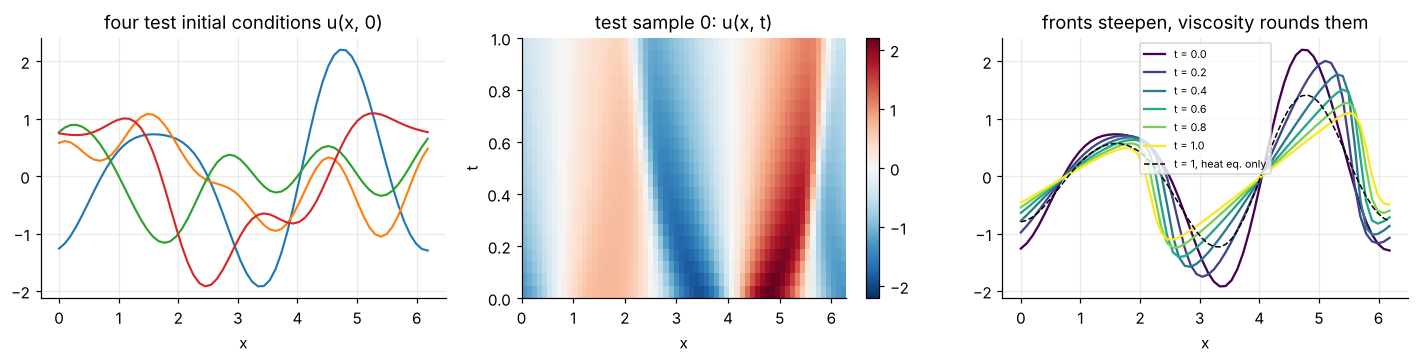

relative difference between Burgers and the heat equation at t = 1: 56%  (advection matters)


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for i in range(4):
    ax[0].plot(x, U_test[i, 0], lw=1.4)
ax[0].set(title="four test initial conditions u(x, 0)", xlabel="x")
im = ax[1].imshow(U_test[SHOW], aspect="auto", origin="lower", cmap="RdBu_r",
                  extent=[0, 2 * np.pi, 0, 1], vmin=-np.abs(U_test[SHOW]).max(), vmax=np.abs(U_test[SHOW]).max())
ax[1].set(title=f"test sample {SHOW}: u(x, t)", xlabel="x", ylabel="t"); fig.colorbar(im, ax=ax[1]); ax[1].grid(False)
cmap = plt.cm.viridis
for j in range(0, 21, 4):
    ax[2].plot(x, U_test[SHOW, j], color=cmap(j / 20), label=f"t = {t[j]:.1f}")
# what pure diffusion would do (no advection): each Fourier mode decays by exp(-nu k^2 t)
k = np.fft.rfftfreq(64, 1 / 64)
heat = np.fft.irfft(np.fft.rfft(U_test[SHOW, 0]) * np.exp(-cfg.nu * k**2), n=64)
ax[2].plot(x, heat, "k--", lw=1, label="t = 1, heat eq. only")
ax[2].set(title="fronts steepen, viscosity rounds them", xlabel="x"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

heat_all = np.fft.irfft(np.fft.rfft(U_test[:, 0]) * np.exp(-cfg.nu * k**2), n=64)
print(f"relative difference between Burgers and the heat equation at t = 1: "
      f"{float(B.relative_l2(heat_all, uT_test)):.0%}  (advection matters)")

## 1. Baseline: a classical solver

**Pseudo-spectral + integrating-factor RK4** (`src/burgers.py`). Space derivatives are taken exactly in Fourier space
(`∂x → ik`), the stiff viscous term is integrated exactly with the factor `exp(−ν k² t)`, and the nonlinear term goes
through RK4 with the 2/3 dealiasing rule. This is the same scheme that generated the data, but run on the 64-point grid
instead of 256, so its error is honest.

For contrast, a **textbook finite-difference** scheme on the same grid (central differences, RK2).

Nothing is learned. The solver knows the PDE exactly and knows nothing about the distribution of initial conditions;
it works for any `u0`, any `ν`, and any `T`, and its error is controlled by the grid and the time step.

Spectral solver (64 pts)     rel. L2 error at T = 0.18%   1.17 ms / sample
Finite differences (64 pts)  rel. L2 error at T = 0.90%   1.62 ms / sample


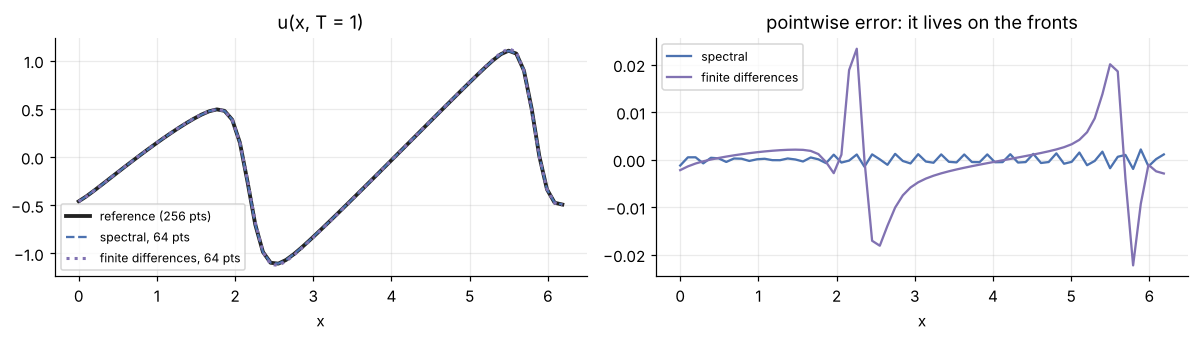

In [4]:
solve_batch = jax.jit(jax.vmap(lambda a: B.solve_config(a, cfg)[-1]))
pred_spec, t_spec = timed(solve_batch, u0_test)
t1 = time.perf_counter(); pred_fd = B.finite_difference_solve(np.asarray(u0_test), cfg.nu, cfg.t_final, cfg.dt)
t_fd = time.perf_counter() - t1
results["Spectral solver (64 pts)"] = dict(key="spectral", err=float(B.relative_l2(pred_spec, uT_test)),
    train_s=0.0, infer_ms=1e3 * t_spec / 64, params=0, data="none", learned="nothing (the PDE is known)")
results["Finite differences (64 pts)"] = dict(key="fd", err=float(B.relative_l2(pred_fd, uT_test)),
    train_s=0.0, infer_ms=1e3 * t_fd / 64, params=0, data="none", learned="nothing (the PDE is known)")
for name in ["Spectral solver (64 pts)", "Finite differences (64 pts)"]:
    r = results[name]; print(f"{name:28s} rel. L2 error at T = {r['err']:.2%}   {r['infer_ms']:.2f} ms / sample")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(x, U_test[SHOW, -1], color=C["truth"], lw=2.5, label="reference (256 pts)")
ax[0].plot(x, pred_spec[SHOW], color=C["spectral"], ls="--", label="spectral, 64 pts")
ax[0].plot(x, pred_fd[SHOW], color=C["fd"], ls=":", lw=2, label="finite differences, 64 pts")
ax[0].set(title="u(x, T = 1)", xlabel="x"); ax[0].legend(fontsize=8)
ax[1].plot(x, pred_spec[SHOW] - U_test[SHOW, -1], color=C["spectral"], label="spectral")
ax[1].plot(x, pred_fd[SHOW] - U_test[SHOW, -1], color=C["fd"], label="finite differences")
ax[1].set(title="pointwise error: it lives on the fronts", xlabel="x"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 2. Differentiable simulation: solving the PDE *backwards* (topic 01)

DiffTaichi and Warp make a simulator differentiable; the notebook in `01-differentiable-simulation/adjoint` derives
the adjoint by hand for a thrown ball. Here the solver of §1 is already written in JAX, so `jax.grad` runs the
discrete adjoint through all 1000 RK4 steps for free. That is not another way to get `u(x, T)`; it is the way to go
from observations back to **unknown inputs**, which none of the learned surrogates below can do as cleanly:

1. **System identification.** We see `u(x, 0)` and `u(x, 1)`. What is the viscosity? (1 unknown)
2. **Initial-state recovery.** We only see `u(x, 1)`. What was `u(x, 0)`? (64 unknowns, and the adjoint costs the
   same one backward pass.) Viscosity erases fine detail, so this is ill-posed; a small smoothness penalty picks the
   smooth answer.

viscosity: true 0.1, recovered 0.0995 (0.5% off) in 100 gradient steps, 7.6 s
initial state: relative error 17.6% after 400 steps, 20.4 s (the naive guess u0 = u(T) is 78% off)


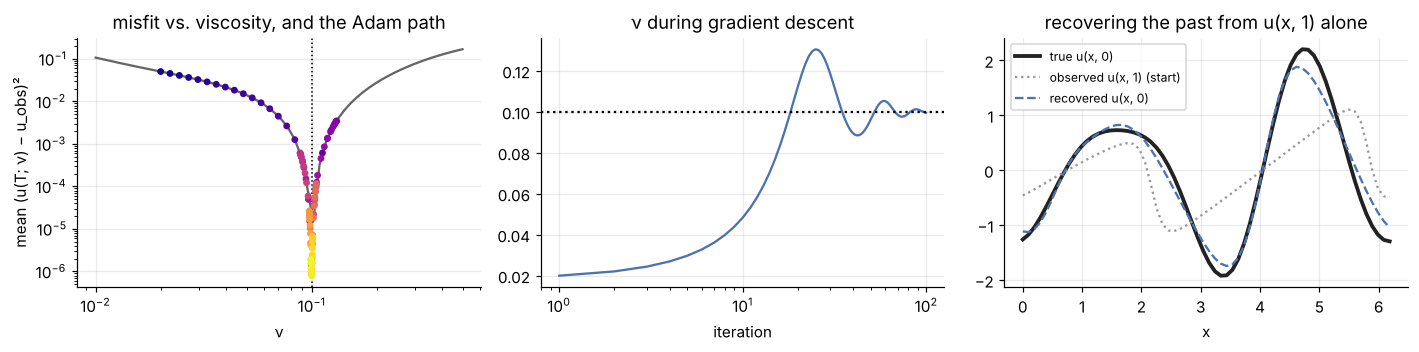

In [5]:
u0_obs, uT_obs = test_set.u[SHOW, 0], test_set.u[SHOW, -1]
t1 = time.perf_counter()
nus, nu_losses = inverse.identify_viscosity(u0_obs, uT_obs, cfg)
t_nu = time.perf_counter() - t1
nu_grid = jnp.geomspace(0.01, 0.5, 60)
landscape = inverse.viscosity_loss_curve(u0_obs, uT_obs, cfg, nu_grid)
t1 = time.perf_counter()
u0_rec, rec_losses = inverse.recover_initial_condition(uT_obs, cfg)
t_rec = time.perf_counter() - t1
err_u0 = float(jnp.linalg.norm(u0_rec - u0_obs) / jnp.linalg.norm(u0_obs))
print(f"viscosity: true {cfg.nu}, recovered {nus[-1]:.4f} ({abs(nus[-1] - cfg.nu) / cfg.nu:.1%} off) "
      f"in {len(nus)} gradient steps, {t_nu:.1f} s")
print(f"initial state: relative error {err_u0:.1%} after {len(rec_losses)} steps, {t_rec:.1f} s "
      f"(the naive guess u0 = u(T) is {float(jnp.linalg.norm(uT_obs - u0_obs) / jnp.linalg.norm(u0_obs)):.0%} off)")
results["Differentiable sim (inverse)"] = dict(key="spectral", err=None, train_s=t_nu + t_rec, infer_ms=None,
    params=0, data="1 observation", learned=f"nu to {abs(nus[-1] - cfg.nu) / cfg.nu:.1%}, u0 to {err_u0:.0%}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].loglog(nu_grid, landscape, color="0.4")
ax[0].scatter(nus, nu_losses, c=np.arange(len(nus)), cmap="plasma", s=12, zorder=3)
ax[0].axvline(cfg.nu, color="k", ls=":", lw=1)
ax[0].set(title="misfit vs. viscosity, and the Adam path", xlabel="ν", ylabel="mean (u(T; ν) − u_obs)²")
ax[1].semilogx(np.arange(1, len(nus) + 1), nus, color=C["spectral"]); ax[1].axhline(cfg.nu, color="k", ls=":")
ax[1].set(title="ν during gradient descent", xlabel="iteration")
ax[2].plot(x, u0_obs, color=C["truth"], lw=2.5, label="true u(x, 0)")
ax[2].plot(x, uT_obs, color="0.6", ls=":", label="observed u(x, 1) (start)")
ax[2].plot(x, u0_rec, color=C["spectral"], ls="--", label="recovered u(x, 0)")
ax[2].set(title="recovering the past from u(x, 1) alone", xlabel="x"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The landscape is smooth and has a single minimum at the true `ν`, so a few dozen gradient steps find it. (The small
bias comes from the solver running on 64 points while the "measurement" was made at 256.) The recovered initial
state has the right fronts and phases but rounded corners: the information about those was diffused away, and no
amount of gradient descent can bring it back.

## 3. Physics-informed neural network (topic 02)

A PINN [Raissi+ 2019] *is* the solution: a network `u_θ(x, t)` trained so that the PDE residual
`u_t + u u_x − ν u_xx` vanishes at random points of space-time. It uses no solver data at all. Two tricks
(`src/pinn.py`) remove the boundary and initial losses so only the residual is left:

* the network sees `(sin x, cos x, t)`, so it is periodic in `x` whatever its weights are;
* `u_θ(x, t) = u0(x) + t · N_θ(x, t)` satisfies the initial condition exactly.

Derivatives come from forward-mode autodiff of the network, not from a grid. **The catch:** one network is one
solution. For a new initial condition the whole training starts again. We therefore train three PINNs, for test
samples 0, 1 and 2.

PINN: rel. L2 error at T = 0.09% (mean over 3 instances), 31 s of training per instance, 7297 parameters


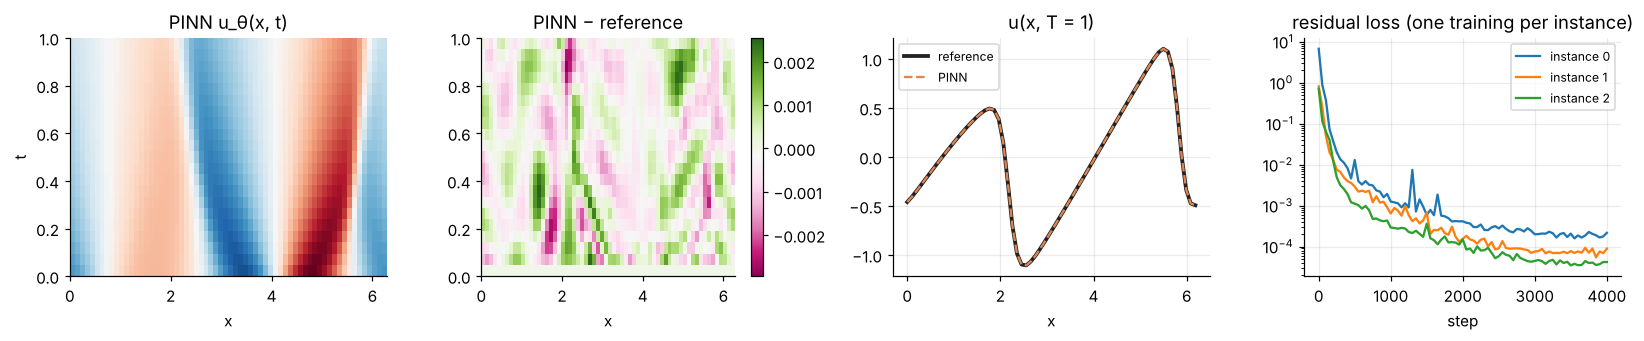

In [6]:
pinn_params, pinn_curves, pinn_times = [], [], []
for i in range(3):
    p0 = pinn.init_pinn(jax.random.PRNGKey(0))
    p, losses, secs = train(pinn.make_loss(test_set.u[i, 0], cfg.nu, cfg.t_final), p0,
                            jax.random.PRNGKey(2), 4000, lr=3e-3, log_every=50)
    pinn_params.append(p); pinn_curves.append(losses); pinn_times.append(secs)
pinn_pred = jnp.stack([pinn.evaluate(p, test_set.u[i, 0], test_set.x, test_set.t) for i, p in enumerate(pinn_params)])
err_pinn = float(B.relative_l2(pinn_pred[:, -1], uT_test[:3]))
print(f"PINN: rel. L2 error at T = {err_pinn:.2%} (mean over 3 instances), "
      f"{np.mean(pinn_times):.0f} s of training per instance, {count_params(pinn_params[0])} parameters")
results["PINN"] = dict(key="pinn", err=err_pinn, train_s=float(np.mean(pinn_times)),
    infer_ms=1e3 * float(np.mean(pinn_times)), params=count_params(pinn_params[0]),
    data="none (PDE only)", learned="one solution u(x, t)")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
vmax = np.abs(U_test[SHOW]).max()
ax[0].imshow(np.asarray(pinn_pred[SHOW]), aspect="auto", origin="lower", cmap="RdBu_r", extent=[0, 2*np.pi, 0, 1],
             vmin=-vmax, vmax=vmax); ax[0].set(title="PINN u_θ(x, t)", xlabel="x", ylabel="t")
im = ax[1].imshow(np.asarray(pinn_pred[SHOW]) - U_test[SHOW], aspect="auto", origin="lower", cmap="PiYG",
                  extent=[0, 2*np.pi, 0, 1]); fig.colorbar(im, ax=ax[1])
ax[1].set(title="PINN − reference", xlabel="x"); ax[0].grid(False); ax[1].grid(False)
ax[2].plot(x, U_test[SHOW, -1], color=C["truth"], lw=2.5, label="reference")
ax[2].plot(x, pinn_pred[SHOW, -1], color=C["pinn"], ls="--", label="PINN"); ax[2].legend(fontsize=8)
ax[2].set(title="u(x, T = 1)", xlabel="x")
for i, c in enumerate(pinn_curves):
    ax[3].semilogy(np.arange(len(c)) * 50, c, label=f"instance {i}")
ax[3].set(title="residual loss (one training per instance)", xlabel="step"); ax[3].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Reduced-order model: POD-Galerkin (topic 03)

CROM [Chen+ 2023] and data-free reduced kinematics [Sharp+ 2023] learn a low-dimensional manifold of states and
evolve the latent coordinates with the known physics. The classical, linear version of that recipe is
**POD-Galerkin** (`src/rom.py`):

1. Stack all training snapshots, take the SVD. The first `r` left singular vectors `Φ` (the POD modes) are the best
   `r`-dimensional linear subspace for that data.
2. Put `u ≈ Φ a` into the PDE and project onto the modes: `da/dt = Φᵀ f(Φ a)`. Because Burgers is quadratic,
   this becomes `da/dt = L a − Q(a, a)` with an `r × r` matrix and an `r × r × r` tensor computed once. The online
   cost no longer depends on the 64 grid points.

What is learned is only the subspace; the dynamics are the PDE's. Two errors add up: the **projection error** (the
true solution is not in the subspace) and the **Galerkin error** (the dropped modes are the ones that dissipate
energy, so the truncated dynamics drift).

r =  4: Galerkin rollout error 40.26%   best possible (projection) 31.52%
r =  8: Galerkin rollout error 20.42%   best possible (projection) 14.61%
r = 12: Galerkin rollout error 10.20%   best possible (projection)  7.89%
r = 16: Galerkin rollout error  5.30%   best possible (projection)  4.39%
r = 24: Galerkin rollout error  1.76%   best possible (projection)  1.58%
r = 32: Galerkin rollout error  0.68%   best possible (projection)  0.63%


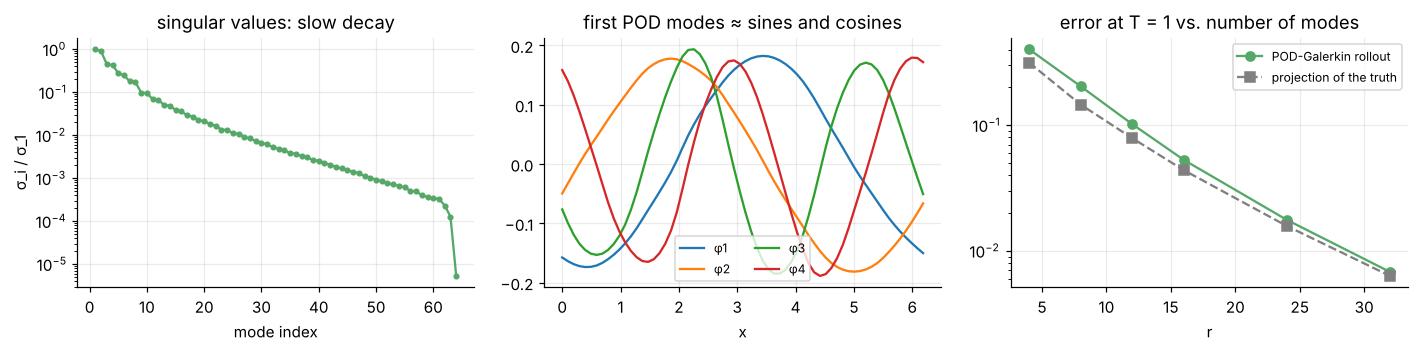

In [7]:
rs = [4, 8, 12, 16, 24, 32]
rom_err, proj_err = [], []
for r in rs:
    m = rom.fit(train_set.u, r, cfg.nu)
    pred = jax.vmap(lambda a: rom.rollout(m, a, cfg.dt, 1000, 50))(u0_test)
    rom_err.append(float(B.relative_l2(pred[:, -1], uT_test)))
    proj_err.append(float(B.relative_l2(rom.decode(m, rom.encode(m, uT_test)), uT_test)))
R = 16
pod = rom.fit(train_set.u, R, cfg.nu)
rom_batch = jax.jit(jax.vmap(lambda a: rom.rollout(pod, a, cfg.dt, 1000, 50)))
rom_pred, t_rom = timed(rom_batch, u0_test)
results[f"POD-Galerkin ROM (r = {R})"] = dict(key="rom", err=float(B.relative_l2(rom_pred[:, -1], uT_test)),
    train_s=0.0, infer_ms=1e3 * t_rom / 64, params=R * 64, data="512 trajectories",
    learned=f"a {R}-dim. linear subspace")
for r, e, p in zip(rs, rom_err, proj_err):
    print(f"r = {r:2d}: Galerkin rollout error {e:6.2%}   best possible (projection) {p:6.2%}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
s = np.asarray(pod.sing)
ax[0].semilogy(np.arange(1, 65), s / s[0], "o-", ms=3, color=C["rom"])
ax[0].set(title="singular values: slow decay", xlabel="mode index", ylabel="σ_i / σ_1")
for i in range(4):
    ax[1].plot(x, pod.phi[:, i], label=f"φ{i+1}")
ax[1].set(title="first POD modes ≈ sines and cosines", xlabel="x"); ax[1].legend(fontsize=8, ncol=2)
ax[2].semilogy(rs, rom_err, "o-", color=C["rom"], label="POD-Galerkin rollout")
ax[2].semilogy(rs, proj_err, "s--", color="0.5", label="projection of the truth")
ax[2].set(title="error at T = 1 vs. number of modes", xlabel="r"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

The modes come out as (nearly) sines and cosines. That is not a coincidence: the data is translation-invariant (a
shifted solution is also a solution), and for translation-invariant data POD *is* the Fourier basis. Sharp fronts need
many Fourier modes, so the singular values decay slowly and 16 modes still leave a few percent of error. This is the
well-known weakness of linear subspaces for advection-dominated problems, and the reason CROM uses a nonlinear
decoder.

## 5. Latent neural ODE (topic 04)

Keep the 16-dimensional POD space, but now **learn the dynamics** instead of projecting the PDE:
`dz/dt = f_θ(z)` with an MLP `f_θ` [Chen+ 2018], in the spirit of latent-space physics [Wiewel+ 2019]
(`src/neural_ode.py`). Training integrates the ODE with RK4 over short windows of 4 snapshot intervals and compares
with the data; `jax.grad` backpropagates through the unrolled integrator (the discrete adjoint again). At test time
the ODE runs over the full 20 intervals from the encoded initial condition.

latent neural ODE: rel. L2 error at T = 7.69%, trained in 72 s


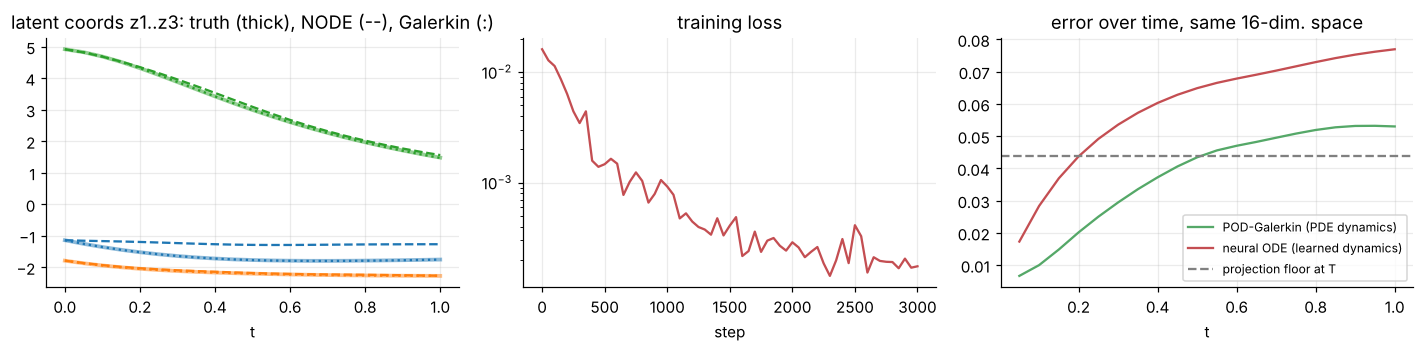

In [8]:
lat = neural_ode.make_latent(pod.phi, train_set.u)
p0 = neural_ode.init_params(jax.random.PRNGKey(0), R)
node_params, node_losses, node_secs = train(neural_ode.make_loss(lat, train_set.u, cfg.t_final, window=4),
                                            p0, jax.random.PRNGKey(1), 3000, lr=3e-3, log_every=50)
node_batch = jax.jit(jax.vmap(lambda a: neural_ode.predict(node_params, lat, a, cfg.t_final, cfg.n_snapshots)))
node_pred, t_node = timed(node_batch, u0_test)
results["Latent neural ODE (r = 16)"] = dict(key="node", err=float(B.relative_l2(node_pred[:, -1], uT_test)),
    train_s=node_secs, infer_ms=1e3 * t_node / 64, params=count_params(node_params), data="512 trajectories",
    learned="dz/dt in the POD space")
print(f"latent neural ODE: rel. L2 error at T = {results['Latent neural ODE (r = 16)']['err']:.2%}, "
      f"trained in {node_secs:.0f} s")

err_t = lambda P: [float(B.relative_l2(P[:, j], test_set.u[:, j])) for j in range(1, 21)]
z_true = np.asarray(test_set.u[SHOW] @ pod.phi); z_node = np.asarray(node_pred[SHOW] @ pod.phi)
z_rom = np.asarray(rom_pred[SHOW] @ pod.phi)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for i, c in zip(range(3), ["C0", "C1", "C2"]):
    ax[0].plot(t, z_true[:, i], color=c, lw=2.5, alpha=0.5)
    ax[0].plot(t, z_node[:, i], color=c, ls="--")
    ax[0].plot(t, z_rom[:, i], color=c, ls=":")
ax[0].set(title="latent coords z1..z3: truth (thick), NODE (--), Galerkin (:)", xlabel="t")
ax[1].semilogy(np.arange(len(node_losses)) * 50, node_losses, color=C["node"])
ax[1].set(title="training loss", xlabel="step")
ax[2].plot(t[1:], err_t(rom_pred), color=C["rom"], label="POD-Galerkin (PDE dynamics)")
ax[2].plot(t[1:], err_t(node_pred), color=C["node"], label="neural ODE (learned dynamics)")
ax[2].axhline(proj_err[rs.index(R)], color="0.5", ls="--", label="projection floor at T")
ax[2].set(title="error over time, same 16-dim. space", xlabel="t"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

Both models live in the same 16-dimensional space, so neither can beat the projection floor. Galerkin uses the exact
equations but ignores the 48 discarded modes; the neural ODE has no equations at all and must learn the dynamics,
including the effect of the discarded modes (a *closure*), from 512 trajectories. With this little data the learned
dynamics are a bit worse than the projected PDE; with more data, or with a hybrid `da/dt = Galerkin(a) + f_θ(a)`, the
learned closure is where a neural ODE earns its keep.

## 6. Graph network simulator (topic 05)

GNS [Sanchez-Gonzalez+ 2020] learns the **time step**. Here (`src/gnn.py`) the graph is the grid: 64 nodes on a ring,
each connected to its neighbours at offsets ±1, ±2, ±3. Node input is `u_i`; edge input is
`(offset · Δx, u_j − u_i)`, only relative quantities, so the model is translation-equivariant like the PDE.
Encode → 3 rounds of message passing → decode gives `Δu_i` over `Δt = 0.05` (50 solver steps), and the model is
rolled out 20 times to reach `T = 1`. As in GNS, training uses one-step pairs with noise added to the inputs, so the
model learns to correct the small errors it will make on its own rollouts.

Seen this way, a GNN on a grid is a *learned, nonlinear finite-difference stencil* with a 19-point reach.

GNS: rel. L2 error at T = 1.76%, trained in 153 s


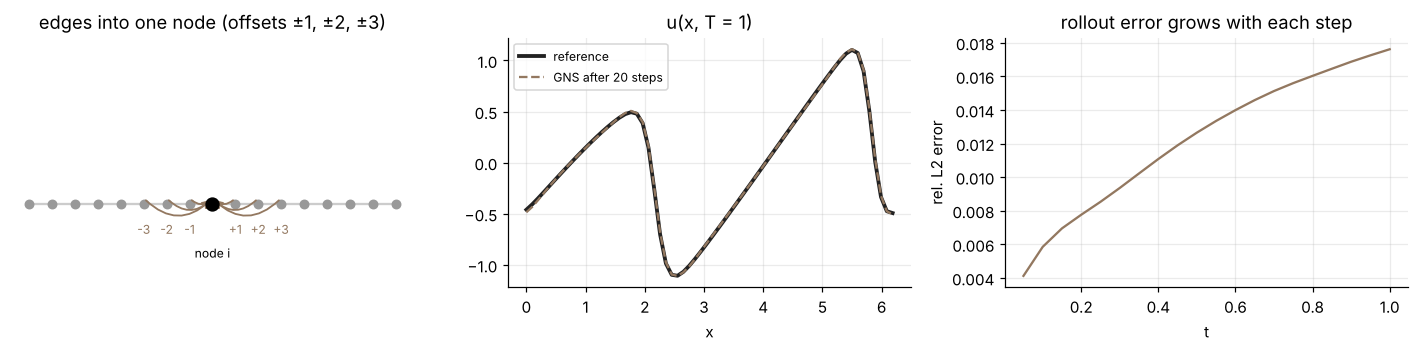

In [9]:
gnn_loss, u_scale, du_scale = gnn.make_loss(train_set.u)
p0 = gnn.init_params(jax.random.PRNGKey(0))
gnn_params, gnn_losses, gnn_secs = train(gnn_loss, p0, jax.random.PRNGKey(1), 1200, lr=1e-3, log_every=25)
gnn_batch = jax.jit(jax.vmap(lambda a: gnn.rollout(gnn_params, a, cfg.n_snapshots, u_scale, du_scale)))
gnn_pred, t_gnn = timed(gnn_batch, u0_test)
results["Graph network (GNS)"] = dict(key="gnn", err=float(B.relative_l2(gnn_pred[:, -1], uT_test)),
    train_s=gnn_secs, infer_ms=1e3 * t_gnn / 64, params=count_params(gnn_params), data="512 trajectories",
    learned="the time step Δt = 0.05")
print(f"GNS: rel. L2 error at T = {results['Graph network (GNS)']['err']:.2%}, trained in {gnn_secs:.0f} s")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
# the stencil of one node: a strip of the ring, with the 6 edges arriving at node i
i0, xs = 8, np.arange(17)
ax[0].plot(xs, np.zeros_like(xs), color="0.8", zorder=0)
ax[0].scatter(xs, np.zeros_like(xs), s=30, color="0.6", zorder=2)
for o in gnn.OFFSETS:
    ax[0].annotate("", xy=(i0, 0.05), xytext=(i0 + o, 0.05),
                   arrowprops=dict(arrowstyle="->", color=C["gnn"], lw=1.2, connectionstyle=f"arc3,rad={-0.5 if o > 0 else 0.5}"))
    ax[0].text(i0 + o, -0.25, f"{o:+d}", ha="center", fontsize=8, color=C["gnn"])
ax[0].scatter([i0], [0], s=70, color="k", zorder=3); ax[0].text(i0, -0.45, "node i", ha="center", fontsize=8)
ax[0].set(title="edges into one node (offsets ±1, ±2, ±3)", xticks=[], yticks=[], ylim=(-0.7, 1.4))
ax[0].grid(False); [sp.set_visible(False) for sp in ax[0].spines.values()]
ax[1].plot(x, U_test[SHOW, -1], color=C["truth"], lw=2.5, label="reference")
ax[1].plot(x, gnn_pred[SHOW, -1], color=C["gnn"], ls="--", label="GNS after 20 steps")
ax[1].set(title="u(x, T = 1)", xlabel="x"); ax[1].legend(fontsize=8)
ax[2].plot(t[1:], err_t(gnn_pred), color=C["gnn"])
ax[2].set(title="rollout error grows with each step", xlabel="t", ylabel="rel. L2 error")
plt.tight_layout(); plt.show()

## 7. Fourier neural operator (topic 06)

From here on the network learns the **solution operator** `G: u(·, 0) ↦ u(·, 1)` in one shot, no time stepping. The
FNO [Li+ 2020] (`src/fno.py`) lifts `(u0, sin x, cos x)` to 32 channels, applies 4 layers of
`v ↦ gelu(W v + IFFT(R · FFT(v)))` keeping 16 Fourier modes, and projects back. The weights `R` are attached to
wavenumbers, not to grid points, so the trained model can be evaluated on a finer grid than it was trained on.

(The separate FNO notebook in `06-neural-operators/fno` takes the operator apart layer by layer; this section only
uses it.)

In [10]:
p0 = fno.init_params(jax.random.PRNGKey(0))
fno_params, fno_losses, fno_secs = train(fno.make_loss(train_set.u[:, 0], train_set.u[:, -1]), p0,
                                         jax.random.PRNGKey(1), 3000, lr=3e-3, log_every=50)
fno_batch = jax.jit(jax.vmap(lambda a: fno.apply(fno_params, a)))
fno_pred, t_fno = timed(fno_batch, u0_test)
results["FNO"] = dict(key="fno", err=float(B.relative_l2(fno_pred, uT_test)), train_s=fno_secs,
    infer_ms=1e3 * t_fno / 64, params=count_params(fno_params), data="512 (u0, u(T)) pairs",
    learned="the operator u(·,0) ↦ u(·,1)")
print(f"FNO: rel. L2 error at T = {results['FNO']['err']:.2%}, trained in {fno_secs:.0f} s, "
      f"{count_params(fno_params)} parameters")

# zero-shot super-resolution: the same initial conditions on finer grids
superres = {}
for n in [64, 128, 256]:
    d = B.make_dataset(jax.random.PRNGKey(11), 64, cfg, n=n)
    superres[n] = (d, float(B.relative_l2(jax.vmap(lambda a: fno.apply(fno_params, a))(d.u[:, 0]), d.u[:, -1])))
print("FNO trained on 64 points, tested on finer grids:",
      {n: f"{e:.2%}" for n, (_, e) in superres.items()})

FNO: rel. L2 error at T = 0.38%, trained in 40 s, 137601 parameters


FNO trained on 64 points, tested on finer grids: {64: '0.38%', 128: '0.38%', 256: '0.38%'}


## 8. Transolver (topics 06 / 07)

Transolver [Wu+ 2024] (`src/transolver.py`) learns the same operator but mixes information globally with attention
instead of an FFT, so it does not need a regular grid. Each point is a token. **Physics-Attention** softly assigns
every point to one of `M = 16` *slices*, averages the points of each slice into one token, runs attention among the
16 slice tokens only, and broadcasts the result back. Cost is linear in the number of points.

The interesting picture is the slice weights: points end up in the same slice because they are in a similar
*physical state* (on a front, on a plateau, rising), not because they are close in `x`.

Transolver: rel. L2 error at T = 5.78%, trained in 150 s
Transolver trained on 64 points, tested on finer grids: {64: '5.78%', 128: '5.78%', 256: '5.78%'}


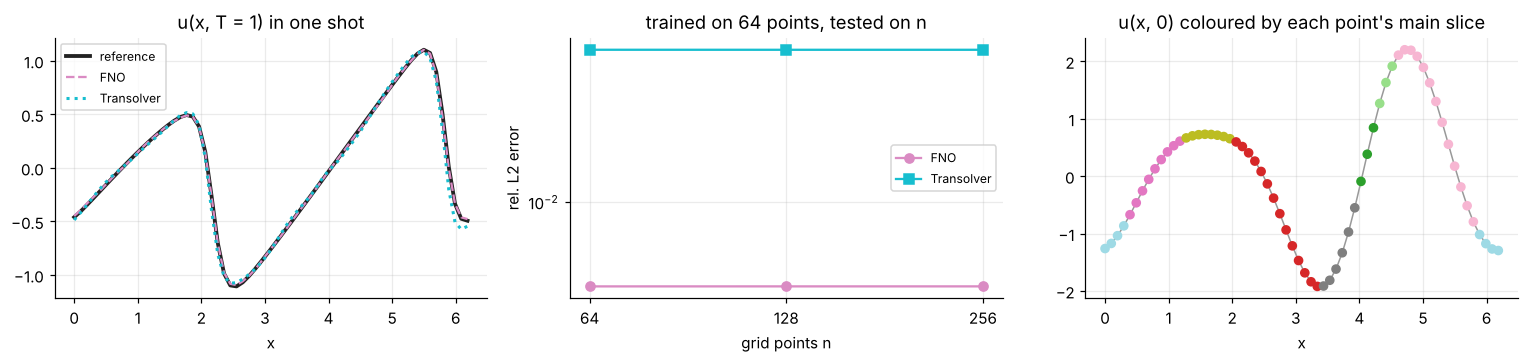

In [11]:
p0 = transolver.init_params(jax.random.PRNGKey(0))
tr_params, tr_losses, tr_secs = train(transolver.make_loss(train_set.u[:, 0], train_set.u[:, -1]), p0,
                                      jax.random.PRNGKey(1), 2000, lr=2e-3, log_every=50)
tr_batch = jax.jit(jax.vmap(lambda a: transolver.apply(tr_params, a)))
tr_pred, t_tr = timed(tr_batch, u0_test)
results["Transolver"] = dict(key="transolver", err=float(B.relative_l2(tr_pred, uT_test)), train_s=tr_secs,
    infer_ms=1e3 * t_tr / 64, params=count_params(tr_params), data="512 (u0, u(T)) pairs",
    learned="the operator u(·,0) ↦ u(·,1)")
tr_superres = {n: float(B.relative_l2(jax.vmap(lambda a: transolver.apply(tr_params, a))(d.u[:, 0]), d.u[:, -1]))
               for n, (d, _) in superres.items()}
print(f"Transolver: rel. L2 error at T = {results['Transolver']['err']:.2%}, trained in {tr_secs:.0f} s")
print("Transolver trained on 64 points, tested on finer grids:", {n: f"{e:.2%}" for n, e in tr_superres.items()})

_, slices = transolver.apply(tr_params, u0_test[SHOW], return_slices=True)
w = np.asarray(slices[0][0])          # layer 1, head 1: (64 points, 16 slices)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].plot(x, U_test[SHOW, -1], color=C["truth"], lw=2.5, label="reference")
ax[0].plot(x, fno_pred[SHOW], color=C["fno"], ls="--", label="FNO")
ax[0].plot(x, tr_pred[SHOW], color=C["transolver"], ls=":", lw=2, label="Transolver")
ax[0].set(title="u(x, T = 1) in one shot", xlabel="x"); ax[0].legend(fontsize=8)
ns = list(superres)
ax[1].plot(ns, [superres[n][1] for n in ns], "o-", color=C["fno"], label="FNO")
ax[1].plot(ns, [tr_superres[n] for n in ns], "s-", color=C["transolver"], label="Transolver")
ax[1].set(xscale="log", yscale="log", xticks=ns, xticklabels=ns, title="trained on 64 points, tested on n",
          xlabel="grid points n", ylabel="rel. L2 error"); ax[1].legend(fontsize=8)
ax[1].minorticks_off()
dom = w.argmax(1)
ax[2].plot(x, U_test[SHOW, 0], color="0.6", lw=1, zorder=1)
sc = ax[2].scatter(x, U_test[SHOW, 0], c=dom, cmap="tab20", s=28, zorder=2, vmin=0, vmax=15)
ax[2].set(title="u(x, 0) coloured by each point's main slice", xlabel="x")
plt.tight_layout(); plt.show()

Points with the same colour share a slice. Slices group points by the *value and shape* of `u0` around them
(peaks, troughs, steep descents), often far apart in `x`; attention then exchanges information between these groups.
On a 64-point regular grid with 512 samples the FNO's built-in Fourier structure is the better inductive bias; the
case for Transolver is irregular meshes and point clouds, where an FFT is not available.

Both operators can be queried on finer grids without retraining, and the error stays flat: the FNO's weights live on
Fourier modes and Transolver's slice tokens are weighted *averages* over points, so neither depends on how many points
there are. (Here the solutions are smooth enough that 64 points already resolve them; on problems with finer detail
than the training grid shows, super-resolution cannot invent it.)

## 9. Comparison

All numbers are the relative L2 error of `u(x, T = 1)` on the 64 held-out initial conditions (the PINN on 3 of them,
since each needs its own training), with wall-clock times from this run on a CPU. "Per new sample" is the time to get
the answer for one new initial condition, batched over 64; for the PINN that is a full training run.

In [12]:
rows = [(k, v) for k, v in results.items()]
hdr = f"{'method':30s} {'rel. L2 at T=1':>14s} {'train (s)':>10s} {'per new sample (ms)':>20s} {'params':>8s}  data needed           what is learned"
print(hdr); print("-" * len(hdr))
for k, v in rows:
    err = "—" if v["err"] is None else f"{v['err']:.2%}"
    inf = "—" if v["infer_ms"] is None else f"{v['infer_ms']:.3g}"
    print(f"{k:30s} {err:>14s} {v['train_s']:>10.0f} {inf:>20s} {v['params']:>8d}  {v['data']:20s}  {v['learned']}")

method                         rel. L2 at T=1  train (s)  per new sample (ms)   params  data needed           what is learned
-----------------------------------------------------------------------------------------------------------------------------
Spectral solver (64 pts)                0.18%          0                 1.17        0  none                  nothing (the PDE is known)
Finite differences (64 pts)             0.90%          0                 1.62        0  none                  nothing (the PDE is known)
Differentiable sim (inverse)                —         28                    —        0  1 observation         nu to 0.5%, u0 to 18%
PINN                                    0.09%         31             3.14e+04     7297  none (PDE only)       one solution u(x, t)
POD-Galerkin ROM (r = 16)               5.30%          0                0.962     1024  512 trajectories      a 16-dim. linear subspace
Latent neural ODE (r = 16)              7.69%         72                0.2

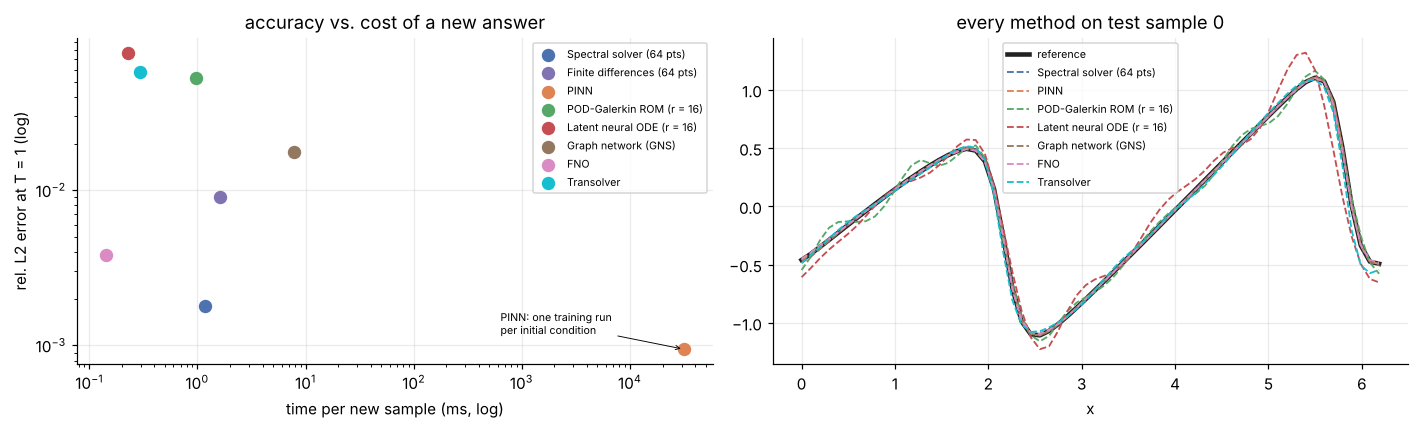

In [13]:
fwd = [(k, v) for k, v in results.items() if v["err"] is not None]
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, v in fwd:
    ax[0].scatter(v["infer_ms"], v["err"], s=60, color=C[v["key"]], label=k, zorder=3)
ax[0].set(xscale="log", yscale="log", xlabel="time per new sample (ms, log)", ylabel="rel. L2 error at T = 1 (log)",
          title="accuracy vs. cost of a new answer"); ax[0].legend(fontsize=7, loc="upper right")
ax[0].annotate("PINN: one training run\nper initial condition", (results["PINN"]["infer_ms"], results["PINN"]["err"]),
               xytext=(-120, 10), textcoords="offset points", fontsize=7, arrowprops=dict(arrowstyle="->", lw=0.6))
ax[1].plot(x, U_test[SHOW, -1], color=C["truth"], lw=3, label="reference", zorder=0)
preds = {"spectral": pred_spec, "pinn": pinn_pred[:, -1], "rom": rom_pred[:, -1], "node": node_pred[:, -1],
         "gnn": gnn_pred[:, -1], "fno": fno_pred, "transolver": tr_pred}
for k, v in fwd:
    if v["key"] in preds:
        ax[1].plot(x, preds[v["key"]][SHOW], color=C[v["key"]], lw=1.2, ls="--", label=k)
ax[1].set(title=f"every method on test sample {SHOW}", xlabel="x"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### What to take away

* **The classical solver is the bar.** On a small periodic 1D problem a spectral solver is accurate to a fraction of
  a percent and costs about a millisecond. No learned method here beats it on accuracy; the surrogates are worth it
  when the solver is expensive (3D, many queries, design loops) or when the physics is only partly known.
* **Differentiable simulation answers a different question.** It is the tool for inverse problems: identify `ν`
  from one observation, or go back in time, with exact gradients and no training data. Its limits are physical
  (information lost to viscosity), not statistical.
* **PINNs are accurate but per-instance.** No data, a continuous `u(x, t)`, ~0.1% error here, and half a minute of
  training for every new initial condition. They shine for one hard instance or with sparse measurements, not for
  many queries.
* **Linear ROMs struggle with fronts.** Translation-invariant, advection-dominated data has POD modes that are
  Fourier modes with slowly decaying energy, which is the motivation for nonlinear manifolds (CROM).
* **Learned dynamics need the right space and enough data.** The latent neural ODE lives in the same space as the
  Galerkin model but must learn the physics from 512 trajectories, and is somewhat worse; in exchange it is a few
  times faster to evaluate, since it takes 100 large RK4 steps instead of 1000 small ones.
* **Local learned steppers (GNS) generalize through locality.** Translation-equivariant by construction, a few
  percent after 20 autoregressive steps; error accumulates with rollout length.
* **Neural operators amortize.** After a minute of training, the FNO answers any new initial condition in one
  forward pass at roughly the spectral solver's accuracy, and runs on finer grids unchanged. Transolver learns the
  same map without assuming a grid, at a higher price on this regular one.

### Where each method sits in the knowledge graph

```
classical solver ──(make it differentiable)──▶ 01 inverse problems
       │
       ├─(drop the grid, fit the residual)──▶ 02 PINN: one u(x,t)
       ├─(project on a data subspace)──────▶ 03 POD-Galerkin ──(learn the latent dynamics)──▶ 04 neural ODE
       ├─(learn the stencil / time step)───▶ 05 GNS
       └─(learn the whole map u0 ↦ u(T))───▶ 06 FNO ──(attention over slices)──▶ 06/07 Transolver
```